In [1]:
from importlib.metadata import version

pkgs = ["matplotlib",
        "osmnx"
       ]
for p in pkgs:
    print(f"{p} version: {version(p)}")

matplotlib version: 3.10.8
osmnx version: 2.0.3


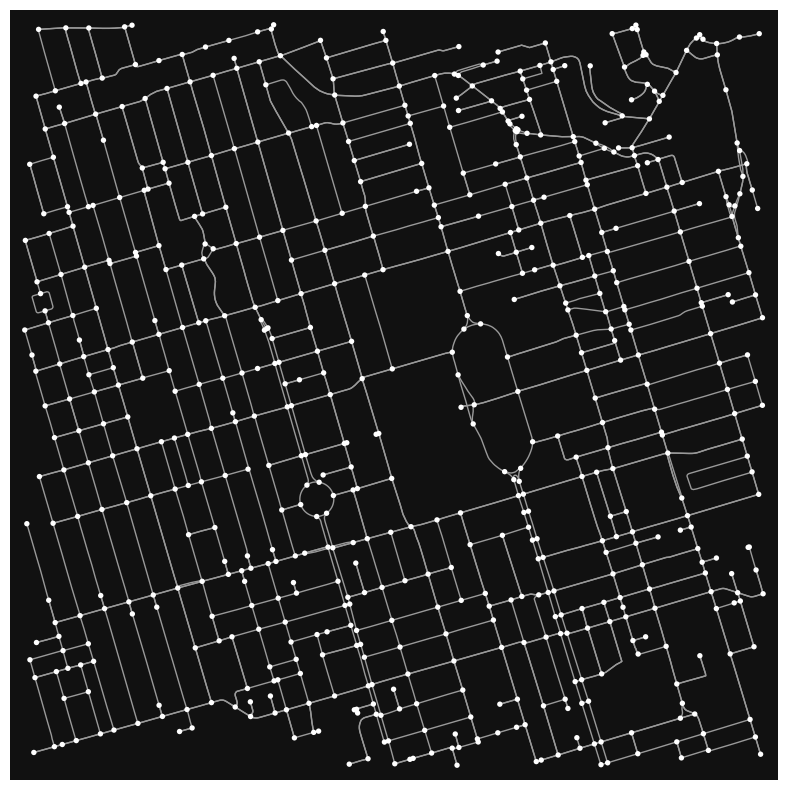

(<Figure size 1000x1000 with 1 Axes>, <Axes: >)

In [2]:
import osmnx as ox

place_name = "University of Toronto"
distance = 1500  # in meters

# fetch OSM street network (drive, walk, private, etc.) from the location
graph = ox.graph_from_address(place_name, dist=distance, network_type='drive') # network_type can be "all", "walk", "bike", "drive", "drive_service"

ox.plot_graph(graph,figsize=(10,10))

In [3]:
import folium

# Convert graph edges to a GeoDataFrame
nodes, edges = ox.graph_to_gdfs(graph)

# Use the graph center as the map center
center_lat = nodes.geometry.y.mean()
center_lon = nodes.geometry.x.mean()

# Create the Folium map
graph_map = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=14,
    tiles="OpenStreetMap"
)

# Add street network to the map
folium.GeoJson(
    edges[["geometry"]].to_json(),
    name="Street network",
    style_function=lambda feature: {
        "color": "blue",
        "weight": 2,
        "opacity": 0.7
    }
).add_to(graph_map)

folium.LayerControl().add_to(graph_map)

# graph_map.save("CH03_F07.html")
graph_map

c:\Users\alaa.rashwan\.conda\envs\agents\Lib\site-packages\geopandas\geodataframe.py:1046: FutureWarning: Starting with NumPy 2.0, the behavior of the 'copy' keyword has changed and passing 'copy=False' raises an error when returning a zero-copy NumPy array is not possible. pandas will follow this behavior starting with pandas 3.0.
This conversion to NumPy requires a copy, but 'copy=False' was passed. Consider using 'np.asarray(..)' instead.
  ids = np.array(self.index, copy=False)


In [4]:
# # Convert hmtl to png
# from html2image import Html2Image
# hti = Html2Image()
# with open('CH03_F07.html') as f:
#     hti.screenshot(f.read(), save_as='CH03_F07.png')